# Cookie Cats A/B test — analysis notebook

This notebook walks through the A/B test analysis: does moving the first gate
from level 30 to level 40 change player retention?

Control = `gate_30` (existing game). Treatment = `gate_40` (new version).

All tests are also in `scripts/run_analysis.py`; this notebook tells the same
story visually.

In [39]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from abtest import stats as ab


DATA = Path("..") / "data" / "raw" / "cookie_cats.csv"
df = pd.read_csv(DATA)
df["retention_1"] = df["retention_1"].astype(int)
df["retention_7"] = df["retention_7"].astype(int)

print("Rows:", len(df))
print("Columns:", list(df.columns))
df.head()

Rows: 90189
Columns: ['userid', 'version', 'sum_gamerounds', 'retention_1', 'retention_7']


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,0,0
1,337,gate_30,38,1,0
2,377,gate_40,165,1,0
3,483,gate_40,1,0,0
4,488,gate_40,179,1,1


## Data checks

Before any test, verify the experiment is healthy:
- Are the groups sized as planned (50/50)?
- Are there any extreme values that will distort means?

In [40]:
ctrl = df[df["version"] == "gate_30"]
treat = df[df["version"] == "gate_40"]

chi2, p_srm = ab.sample_ratio_mismatch(len(ctrl), len(treat))
print(f"gate_30: {len(ctrl):,} players")
print(f"gate_40: {len(treat):,} players")
print(f"Sample ratio check: chi2 = {chi2:.2f}, p = {p_srm:.4f}")
print(f"Max rounds (all groups): {df['sum_gamerounds'].max():,}")

gate_30: 44,700 players
gate_40: 45,489 players
Sample ratio check: chi2 = 6.90, p = 0.0086
Max rounds (all groups): 49,854


## Retention by version

A simple comparison of the primary metric (day-7 retention) and the guardrail
(day-1 retention) between the two groups.

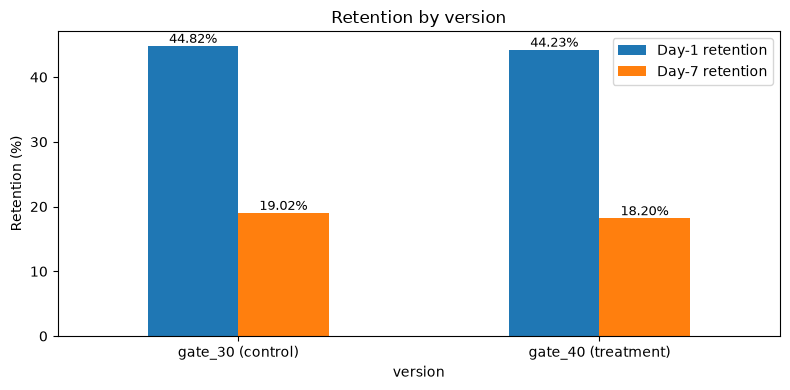

In [41]:
rates = df.groupby("version")[["retention_1", "retention_7"]].mean() * 100
rates.columns = ["Day-1 retention", "Day-7 retention"]
ax = rates.plot(kind="bar", figsize=(8, 4))
ax.set_ylabel("Retention (%)")
ax.set_title("Retention by version")
ax.set_xticklabels(["gate_30 (control)", "gate_40 (treatment)"], rotation=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

## Distribution of game rounds

Most players play very few rounds; a few play thousands. This is why the
mean of game rounds is unreliable and we use medians and trimmed methods.

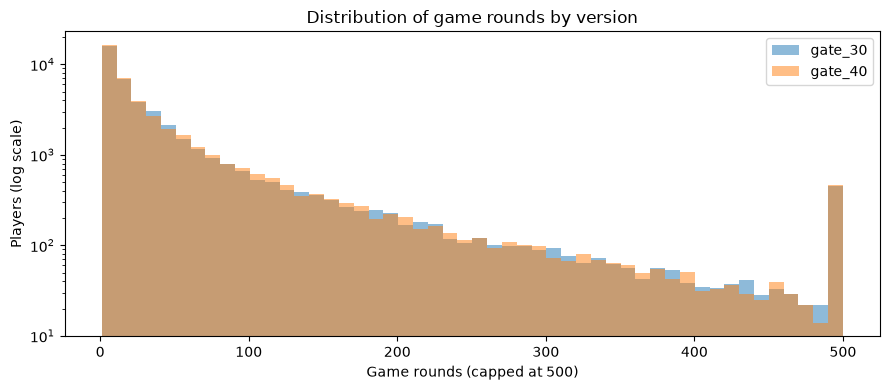

In [42]:
fig, ax = plt.subplots(figsize=(9, 4))
for version, g in df.groupby("version"):
    rounds = g.loc[g["sum_gamerounds"] > 0, "sum_gamerounds"].clip(upper=500)
    ax.hist(rounds, bins=50, alpha=0.5, label=version)

ax.set_yscale("log")
ax.set_xlabel("Game rounds (capped at 500)")
ax.set_ylabel("Players (log scale)")
ax.set_title("Distribution of game rounds by version")
ax.legend()
plt.tight_layout()
plt.show()

## Primary result — day-7 retention

The two-proportion z-test on the primary metric, with a confidence interval
and a bootstrap cross-check.

In [43]:
r7 = ab.two_proportion_test(
    x_control=int(ctrl["retention_7"].sum()), n_control=len(ctrl),
    x_treatment=int(treat["retention_7"].sum()), n_treatment=len(treat),
    alpha=0.05,
)
boot = ab.bootstrap_diff(
    x_control=int(ctrl["retention_7"].sum()), n_control=len(ctrl),
    x_treatment=int(treat["retention_7"].sum()), n_treatment=len(treat),
)

print(f"gate_30: {100*r7.p_control:.2f}%")
print(f"gate_40: {100*r7.p_treatment:.2f}%")
print(f"Difference: {100*r7.diff:+.2f} pp")
print(f"95% CI: {100*r7.ci_low:+.2f} to {100*r7.ci_high:+.2f} pp")
print(f"p-value: {r7.p_value:.4f}")
print(f"Bootstrap CI: {100*boot['ci_low']:+.2f} to {100*boot['ci_high']:+.2f} pp")

decision = ab.classify_result(r7.ci_low, r7.ci_high, 0.005)
print(f"Decision: {decision}")
print(ab.DECISION_TEXT[decision])

gate_30: 19.02%
gate_40: 18.20%
Difference: -0.82 pp
95% CI: -1.33 to -0.31 pp
p-value: 0.0016
Bootstrap CI: -1.34 to -0.31 pp
Decision: inconclusive
Inconclusive: the data cannot rule out a meaningful effect either way.


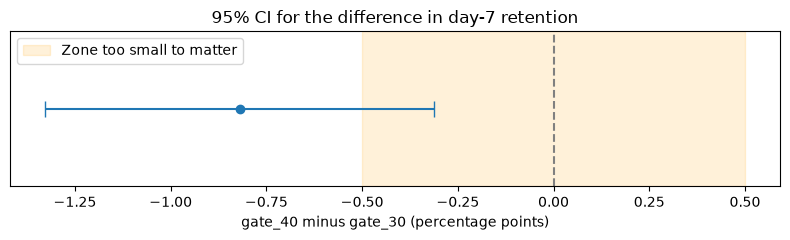

In [44]:
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.errorbar(100 * r7.diff, 0,
            xerr=[[100 * (r7.diff - r7.ci_low)],
                  [100 * (r7.ci_high - r7.diff)]],
            fmt="o", color="C0", capsize=6)
ax.axvline(0, linestyle="--", color="gray")
ax.axvspan(-0.5, 0.5, alpha=0.15, color="orange", label="Zone too small to matter")
ax.set_xlabel("gate_40 minus gate_30 (percentage points)")
ax.set_yticks([])
ax.set_title("95% CI for the difference in day-7 retention")
ax.legend()
plt.tight_layout()
plt.show()

## Secondary metrics

Day-1 retention (guardrail) and game rounds (engagement). Because three tests
were run, p-values are adjusted using Holm correction.

In [45]:
from scipy import stats as sps

r1 = ab.two_proportion_test(
    x_control=int(ctrl["retention_1"].sum()), n_control=len(ctrl),
    x_treatment=int(treat["retention_1"].sum()), n_treatment=len(treat),
)

mw = sps.mannwhitneyu(ctrl["sum_gamerounds"], treat["sum_gamerounds"],
                      alternative="two-sided")

print("Day-1 retention:")
print(f"  gate_30: {100*r1.p_control:.2f}%  gate_40: {100*r1.p_treatment:.2f}%")
print(f"  diff {100*r1.diff:+.2f} pp, 95% CI {100*r1.ci_low:+.2f} to {100*r1.ci_high:+.2f} pp")
print(f"  p = {r1.p_value:.4f}")

print("\nGame rounds, Mann-Whitney U:")
print(f"  p = {mw.pvalue:.4f}")
print(f"  medians: gate_30 = {ctrl['sum_gamerounds'].median():.0f}, "
      f"gate_40 = {treat['sum_gamerounds'].median():.0f}")
# Trimmed Welch test
rc_trim = ctrl["sum_gamerounds"][ctrl["sum_gamerounds"] <= ctrl["sum_gamerounds"].quantile(0.999)]
rt_trim = treat["sum_gamerounds"][treat["sum_gamerounds"] <= treat["sum_gamerounds"].quantile(0.999)]
w = ab.welch_from_summary(
    rc_trim.mean(), rc_trim.std(), len(rc_trim),
    rt_trim.mean(), rt_trim.std(), len(rt_trim),
)

adjusted = ab.holm_adjust({
    "day1": float(r1.p_value),
    "rounds_mw": float(mw.pvalue),
    "rounds_welch_trim": w["p_value"],
})
print("\nHolm-adjusted p-values:")
for k, v in adjusted.items():
    print(f"  {k}: {v:.4f}")

Day-1 retention:
  gate_30: 44.82%  gate_40: 44.23%
  diff -0.59 pp, 95% CI -1.24 to +0.06 pp
  p = 0.0744

Game rounds, Mann-Whitney U:
  p = 0.0502
  medians: gate_30 = 17, gate_40 = 16

Holm-adjusted p-values:
  rounds_mw: 0.1506
  day1: 0.1506
  rounds_welch_trim: 0.8699


## Power

How small an effect could this test reliably detect? And how many players
would be needed to detect the 0.5 pp threshold from the plan?

In [46]:
n_per_group = min(len(ctrl), len(treat))
mde = ab.minimum_detectable_effect(r7.p_control, n_per_group)
need = ab.required_n_per_group(r7.p_control, 0.005)

print(f"With {n_per_group:,} per group and baseline {100*r7.p_control:.2f}%:")
print(f"  Smallest detectable effect at 80% power: {100*mde:.2f} pp")
print(f"  Players needed to detect 0.5 pp: {need:,} per group")

With 44,700 per group and baseline 19.02%:
  Smallest detectable effect at 80% power: 0.74 pp
  Players needed to detect 0.5 pp: 97,682 per group


## Conclusion

The primary metric (day-7 retention) shows a statistically significant decrease
in gate_40, but the confidence interval straddles the practical threshold of
0.5 pp. The test was powered for effects of 0.74 pp or larger, but not for the
0.5 pp threshold from the plan.

Decision rule: **inconclusive**. The data suggests gate_40 may be worse, but
more players are needed to resolve the ambiguity.

No secondary metric shows a significant effect after Holm correction.

In [47]:
print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Day-7 retention diff: {100*r7.diff:+.2f} pp "
      f"(95% CI {100*r7.ci_low:+.2f} to {100*r7.ci_high:+.2f} pp, "
      f"p = {r7.p_value:.4f})")
print(f"Decision rule: {decision}")
print(f"MDE with current sample: {100*mde:.2f} pp")
print(f"Required n for 0.5 pp: {need:,} per group")

SUMMARY
Day-7 retention diff: -0.82 pp (95% CI -1.33 to -0.31 pp, p = 0.0016)
Decision rule: inconclusive
MDE with current sample: 0.74 pp
Required n for 0.5 pp: 97,682 per group
